In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('loan.csv')
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
df.shape

(614, 13)

In [4]:
print('rows : ',df.shape[0]) 
print('columns : ',df.shape[1]) 

rows :  614
columns :  13


In [5]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [6]:
df.isnull()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,False,False,False,False,False,False,False,False,True,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,False,False,False,False,False,False,False,False,False,False,False,False,False
610,False,False,False,False,False,False,False,False,False,False,False,False,False
611,False,False,False,False,False,False,False,False,False,False,False,False,False
612,False,False,False,False,False,False,False,False,False,False,False,False,False


In [7]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [8]:
miss_percent = (df.isnull().sum()/len(df))*100
print('missing percentage : ',miss_percent)

missing percentage :  Loan_ID              0.000000
Gender               2.117264
Married              0.488599
Dependents           2.442997
Education            0.000000
Self_Employed        5.211726
ApplicantIncome      0.000000
CoapplicantIncome    0.000000
LoanAmount           3.583062
Loan_Amount_Term     2.280130
Credit_History       8.143322
Property_Area        0.000000
Loan_Status          0.000000
dtype: float64


In [9]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [10]:
Q1 = df['ApplicantIncome'].quantile(0.25)
Q2 = df["ApplicantIncome"].quantile(0.50)
Q3 = df['ApplicantIncome'].quantile(0.75)
min_ = df['ApplicantIncome'].min()
max_ = df['ApplicantIncome'].max()
print('Q1 : ',Q1)
print('Q2 : ',Q2)
print('Q3 : ',Q3)
print('Min_ : ',min_)
print('Max_ : ',max_)
IQR = Q3 - Q1
print('IQR : ',IQR)
lower_limit = Q1 - 1.5*IQR
upper_limit = Q3 + 1.5*IQR
print('Lower_limit : ',lower_limit)
print('Upper_limit : ',upper_limit)

Q1 :  2877.5
Q2 :  3812.5
Q3 :  5795.0
Min_ :  150
Max_ :  81000
IQR :  2917.5
Lower_limit :  -1498.75
Upper_limit :  10171.25


In [11]:
outliers = df[
    (df["ApplicantIncome"] < lower_limit) | (df["ApplicantIncome"] > upper_limit) 
]

print("Total outliers:", len(outliers))

Total outliers: 50


In [15]:
outliers[["Loan_ID", "ApplicantIncome"]].head(10)

,Loan_ID,ApplicantIncome
9,LP001020,12841
34,LP001100,12500
54,LP001186,11500
67,LP001233,10750
102,LP001350,13650
106,LP001369,11417
115,LP001401,14583
119,LP001422,10408
126,LP001448,23803
128,LP001451,10513


In [16]:
a = outliers[["Loan_ID", "ApplicantIncome"]].sort_values(by="ApplicantIncome").head()
a

,Loan_ID,ApplicantIncome
119,LP001422,10408
438,LP002403,10416
128,LP001451,10513
67,LP001233,10750
483,LP002541,10833


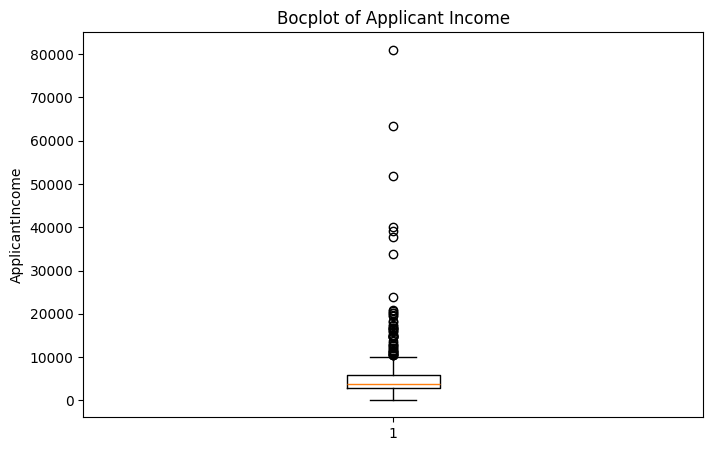

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5)) # Set the figure size
plt.boxplot(df['ApplicantIncome'].dropna())
# .dropna() removes missing values (NaN) before plotting.
plt.title('Bocplot of Applicant Income')
plt.ylabel('ApplicantIncome')
plt.show()

In [18]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [19]:
numerical_cols = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term'
]
for cols in numerical_cols :
    data = df[cols].dropna()
    Q1 = data.quantile(0.25)
    Q2 = data.quantile(0.50)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3  + 1.5 * IQR
    outlier_count = (
        (data < lower_limit) | (data > upper_limit)
    ).sum()
    print(f" {cols} : {outlier_count} possible outliers")

 ApplicantIncome : 50 possible outliers
 CoapplicantIncome : 18 possible outliers
 LoanAmount : 39 possible outliers
 Loan_Amount_Term : 88 possible outliers


'Credit_History ko abhi include nahi kar rahe, kyunki usmein 0 aur 1 jaise binary values hain; use numerical continuous data\n    se alag handle karna behtar hai.'

In [20]:
df_clean = df.copy()
print("original dataset shape : ",df.shape)
print("working dataset : ",df_clean.shape)

original dataset shape :  (614, 13)
working dataset :  (614, 13)


In [21]:
print('Gender mode : ',df_clean['Gender'].mode()[0])

Gender mode :  Male


In [22]:
df_clean['Gender'] = df_clean['Gender'].fillna(
    df_clean['Gender'].mode()[0]
)
print('Missing Gender value : ',df_clean['Gender'].isnull().sum())

Missing Gender value :  0


In [23]:
a = df_clean['Married'].isnull().sum() 
print('missing maried status : ',a)

missing maried status :  3


In [24]:
print('Married mode : ',df_clean['Married'].mode()[0]) 

Married mode :  Yes


In [25]:
df_clean['Married'] = df_clean['Married'].fillna(
    df_clean['Married'].mode()[0]
)
print('Missing Married Status : ',df_clean['Married'].isnull().sum())

Missing Married Status :  0


In [26]:
print('Original married values : ')
print(df['Married'].value_counts(dropna = False))
print()
print('Cleaned Married values : ')
print(df_clean['Married'].value_counts(dropna = False))

Original married values : 
Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64

Cleaned Married values : 
Married
Yes    401
No     213
Name: count, dtype: int64


In [27]:
print('missed Dependents : ',df_clean['Dependents'].isnull().sum())

missed Dependents :  15


In [28]:
print('Dependents mode : ',df_clean['Dependents'].mode()[0])

Dependents mode :  0


In [29]:
df_clean['Dependents'] = df_clean['Dependents'].fillna(
    df_clean['Dependents'].mode()[0]
)
print('Missed Dependents : ',df_clean['Dependents'].isnull().sum())

Missed Dependents :  0


In [30]:
print('missed Self_Employed : ', df['Self_Employed'].isnull().sum())

missed Self_Employed :  32


In [31]:
print('mode of Self_Employed : ',df_clean['Self_Employed'].mode()[0])

mode of Self_Employed :  No


In [32]:
df_clean['Self_Employed'] = df_clean['Self_Employed'].fillna(
    df_clean['Self_Employed'].mode()[0]
)
print('Missing Self_Employed values : ',df_clean['Self_Employed'].isnull().sum())

Missing Self_Employed values :  0


In [33]:
print('missing loan amount : ',df_clean['LoanAmount'].isnull().sum())

missing loan amount :  22


In [34]:
print('LoanAmount median : ', df_clean['LoanAmount'].median())

LoanAmount median :  128.0


In [36]:
df_clean['LoanAmount'] = df_clean['LoanAmount'].fillna(
    df_clean['LoanAmount'].median()
)
print('Missing loanAmount values : ',df_clean['LoanAmount'].isnull().sum())

Missing loanAmount values :  0


In [37]:
print('missing Loan_Amount_Term : ',df_clean['Loan_Amount_Term'].isnull().sum())

missing Loan_Amount_Term :  14


In [38]:
print('median of Loan_Amount_Term : ',df_clean['Loan_Amount_Term'].median())

median of Loan_Amount_Term :  360.0


In [39]:
df_clean['Loan_Amount_Term'] = df_clean['Loan_Amount_Term'].fillna(
    df_clean['Loan_Amount_Term'].median()
)
print('missing Loan_Amount_Term : ',df_clean['Loan_Amount_Term'].isnull().sum())

missing Loan_Amount_Term :  0


In [40]:
print('missed Credit_History : ',df_clean['Credit_History'].isnull().sum())

missed Credit_History :  50


In [41]:
print('mode of Credit_History : ',df_clean['Credit_History'].mode()[0])

mode of Credit_History :  1.0


In [42]:
df_clean['Credit_History'] = df_clean['Credit_History'].fillna(
    df_clean['Credit_History'].mode()[0]
)
print('missing Credit_History : ',df_clean['Credit_History'].isnull().sum())

missing Credit_History :  0


In [43]:
print("Missing values in each column:")
print(df_clean.isnull().sum())

print("\nTotal missing values:",
      df_clean.isnull().sum().sum())

Missing values in each column:
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

Total missing values: 0


In [44]:
print('Total Duplicate Rows : ',df_clean.duplicated().sum())

Total Duplicate Rows :  0


In [45]:
categorical_columns = df_clean.select_dtypes(include='object').columns
for col in categorical_columns :
    print(f"\nUnique Values in {col} : ")
    print(df_clean[col].unique())


Unique Values in Loan_ID : 
['LP001002' 'LP001003' 'LP001005' 'LP001006' 'LP001008' 'LP001011'
 'LP001013' 'LP001014' 'LP001018' 'LP001020' 'LP001024' 'LP001027'
 'LP001028' 'LP001029' 'LP001030' 'LP001032' 'LP001034' 'LP001036'
 'LP001038' 'LP001041' 'LP001043' 'LP001046' 'LP001047' 'LP001050'
 'LP001052' 'LP001066' 'LP001068' 'LP001073' 'LP001086' 'LP001087'
 'LP001091' 'LP001095' 'LP001097' 'LP001098' 'LP001100' 'LP001106'
 'LP001109' 'LP001112' 'LP001114' 'LP001116' 'LP001119' 'LP001120'
 'LP001123' 'LP001131' 'LP001136' 'LP001137' 'LP001138' 'LP001144'
 'LP001146' 'LP001151' 'LP001155' 'LP001157' 'LP001164' 'LP001179'
 'LP001186' 'LP001194' 'LP001195' 'LP001197' 'LP001198' 'LP001199'
 'LP001205' 'LP001206' 'LP001207' 'LP001213' 'LP001222' 'LP001225'
 'LP001228' 'LP001233' 'LP001238' 'LP001241' 'LP001243' 'LP001245'
 'LP001248' 'LP001250' 'LP001253' 'LP001255' 'LP001256' 'LP001259'
 'LP001263' 'LP001264' 'LP001265' 'LP001266' 'LP001267' 'LP001273'
 'LP001275' 'LP001279' 'LP001280'

In [46]:
print('Original married values : ')
print(df['Married'].value_counts(dropna = False))
print()
print('Cleaned Married values : ')
print(df_clean['Married'].value_counts(dropna = False))

Original married values : 
Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64

Cleaned Married values : 
Married
Yes    401
No     213
Name: count, dtype: int64


In [47]:
columns_to_check = [
    'Gender',
    'Dependents',
    'Self_Employed',
    'LoanAmount',
    'Loan_Amount_Term',
    'Credit_History'
]
for col in columns_to_check :
    original_non_missing = df[col].notna()

    unchanged = (
        df.loc[original_non_missing, col].reset_index(drop = True)
        == df_clean.loc[original_non_missing, col].reset_index(drop = True)
    ).all()

    print(f"{col} : original values unchanged = {unchanged}")

Gender : original values unchanged = True
Dependents : original values unchanged = True
Self_Employed : original values unchanged = True
LoanAmount : original values unchanged = True
Loan_Amount_Term : original values unchanged = True
Credit_History : original values unchanged = True


In [48]:
numerical_columns = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term',
    'Credit_History'
]

for col in numerical_columns :
    print(f"\n{col}")
    print('Minimum Value : ',df_clean[col].min())
    print('Maximum Value : ',df_clean[col].max())
    print('Negative Value : ',(df_clean[col] < 0).sum())


ApplicantIncome
Minimum Value :  150
Maximum Value :  81000
Negative Value :  0

CoapplicantIncome
Minimum Value :  0.0
Maximum Value :  41667.0
Negative Value :  0

LoanAmount
Minimum Value :  9.0
Maximum Value :  700.0
Negative Value :  0

Loan_Amount_Term
Minimum Value :  12.0
Maximum Value :  480.0
Negative Value :  0

Credit_History
Minimum Value :  0.0
Maximum Value :  1.0
Negative Value :  0


In [49]:
print('Credit History Unique Value : ')
print(df_clean['Credit_History'].unique())

print('\nCredit History Value Counts : ')
print(df_clean['Credit_History'].value_counts())

Credit History Unique Value : 
[1. 0.]

Credit History Value Counts : 
Credit_History
1.0    525
0.0     89
Name: count, dtype: int64


In [50]:
print("Loan_Amount_Term unique values:")
print(sorted(df_clean["Loan_Amount_Term"].unique()))

print("\nLoan_Amount_Term value counts:")
print(df_clean["Loan_Amount_Term"].value_counts().sort_index())

Loan_Amount_Term unique values:
[np.float64(12.0), np.float64(36.0), np.float64(60.0), np.float64(84.0), np.float64(120.0), np.float64(180.0), np.float64(240.0), np.float64(300.0), np.float64(360.0), np.float64(480.0)]

Loan_Amount_Term value counts:
Loan_Amount_Term
12.0       1
36.0       2
60.0       2
84.0       4
120.0      3
180.0     44
240.0      4
300.0     13
360.0    526
480.0     15
Name: count, dtype: int64


In [51]:
print("Dependents unique values:")
print(df_clean["Dependents"].unique())

print("\nDependents value counts:")
print(df_clean["Dependents"].value_counts())

Dependents unique values:
['0' '1' '2' '3+']

Dependents value counts:
Dependents
0     360
1     102
2     101
3+     51
Name: count, dtype: int64


In [52]:
Q1 = df_clean["LoanAmount"].quantile(0.25)
Q3 = df_clean["LoanAmount"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["LoanAmount"] < lower_limit) |
    (df_clean["LoanAmount"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of possible outliers:", len(outliers))

print("\nHighest loan amounts:")
print(df_clean["LoanAmount"].nlargest(10).to_list())

Q1: 100.25
Q3: 164.75
IQR: 64.5
Lower Limit: 3.5
Upper Limit: 261.5
Number of possible outliers: 41

Highest loan amounts:
[700.0, 650.0, 600.0, 600.0, 570.0, 500.0, 496.0, 495.0, 490.0, 480.0]


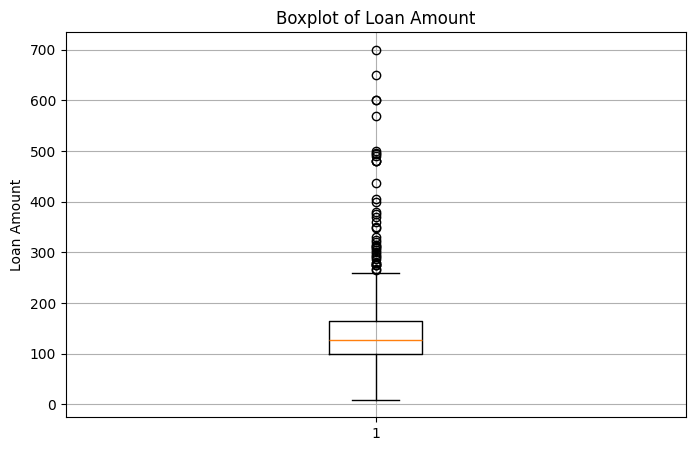

In [55]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.boxplot(df_clean["LoanAmount"])
plt.title("Boxplot of Loan Amount")
plt.ylabel("Loan Amount")
plt.grid(True)
plt.show()

In [56]:
Q1 = df_clean["ApplicantIncome"].quantile(0.25)
Q3 = df_clean["ApplicantIncome"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["ApplicantIncome"] < lower_limit) |
    (df_clean["ApplicantIncome"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of possible outliers:", len(outliers))
print("Highest incomes:")
print(df_clean["ApplicantIncome"].nlargest(10).to_list())

Lower Limit: -1498.75
Upper Limit: 10171.25
Number of possible outliers: 50
Highest incomes:
[81000, 63337, 51763, 39999, 39147, 37719, 33846, 23803, 20833, 20667]


In [57]:
Q1 = df_clean["CoapplicantIncome"].quantile(0.25)
Q3 = df_clean["CoapplicantIncome"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["CoapplicantIncome"] < lower_limit) |
    (df_clean["CoapplicantIncome"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of possible outliers:", len(outliers))
print("Highest co-applicant incomes:")
print(df_clean["CoapplicantIncome"].nlargest(10).to_list())

Lower Limit: -3445.875
Upper Limit: 5743.125
Number of possible outliers: 18
Highest co-applicant incomes:
[41667.0, 33837.0, 20000.0, 20000.0, 11300.0, 10968.0, 8980.0, 8333.0, 8106.0, 7873.0]


In [ ]:
# Outlier analysis ka summary
numerical_columns = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]

for col in numerical_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df_clean[col] < lower_limit) |
        (df_clean[col] > upper_limit)
    ).sum()

    print(
        f"{col}: Lower={lower_limit:.2f}, "
        f"Upper={upper_limit:.2f}, "
        f"Possible outliers={outlier_count}"
    )